# sigflow tour

Typed, functional, generator-based signal-processing graphs. This notebook walks through
blocks, composition, compile-time type checking, annotations, error propagation,
provenance, mixed sync/async streams, live progress and plotting.

In [1]:
# If `sigflow` was installed into a different Python than this kernel uses,
# fall back to the package source that sits next to this notebook (../src).
import sys, pathlib

try:
    import sigflow
except ModuleNotFoundError:
    sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))
    import sigflow
print(
    "sigflow",
    sigflow.__version__,
    "from",
    pathlib.Path(sigflow.__file__).parent,
    "| kernel:",
    sys.executable,
)

sigflow 0.2.0 from /home/claude/sigflow/src/sigflow | kernel: /usr/bin/python3


In [2]:
import numpy as np
import matplotlib

%matplotlib inline
from sigflow import Sig, Stream, Framed, Frame, TypeMismatch, block, source, run
from sigflow import dsp, linalg, plot

## 1. Blocks are plain functions with typed signatures
Parameters annotated with `Sig[...]` are inputs; everything else is configuration fixed when the block
is placed in a graph. `"T"` is a dtype variable, `"N"` a symbolic dimension.

In [3]:
@block
def scale(x: Sig["T", "N"], gain: float = 1.0) -> Sig["T", "N"]:
    return x * gain


@block
def energy(x: Sig["T", "N"]) -> Sig[float, ()]:
    return float(np.sum(np.abs(x) ** 2))


scale(np.arange(4.0), gain=2)  # still an ordinary function

array([0., 2., 4., 6.])

## 2. Compose with operators; the graph is type-checked as you build it
A graph renders as a table in Jupyter.

In [4]:
g = (
    dsp.sine(freq=1000, rate=48_000, n=1024, frames=20)
    >> dsp.window
    >> dsp.to_complex
    >> dsp.fft
    >> dsp.power_db
)
g

node,in,out,kind
"sine(freq=1000, rate=48000, n=1024, frames=20, amplitude=1.0, phase=0.0)",,"Sig[float64, (1024,)]",source
window(kind='hann'),"Sig[T, (N,)]","Sig[T, (N,)]",map
to_complex(),"Sig[float64, (N,)]","Sig[complex128, (N,)]",map
"fft(n=None, axis=-1, norm=None, out=None)","Sig[complex128, (N,)]","Sig[complex128, (N,)]",map
power_db(floor=1e-12),"Sig[complex128, (N,)]","Sig[float64, (N,), _, 'dB']",map


`g.draw()` renders the topology as an SVG (hover a box for its full signature); `g.to_dot()` exports Graphviz.

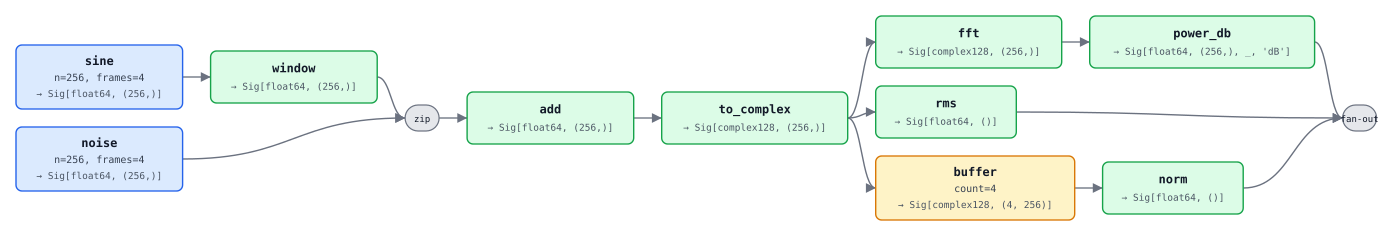

In [5]:
@block
def add(a: Sig["T", "N"], b: Sig["T", "N"]) -> Sig["T", "N"]:
    return a + b


big = (
    ((dsp.sine(n=256, frames=4) >> dsp.window) & dsp.noise(n=256, frames=4))
    >> add
    >> dsp.to_complex
    >> (dsp.fft >> dsp.power_db | dsp.rms | dsp.buffer(count=4) >> linalg.norm)
)
big.draw()

In [6]:
try:
    dsp.sine() >> energy >> scale  # scalar cannot feed a vector
except TypeMismatch as e:
    print("rejected:", e)

try:
    (dsp.sine(n=64) & dsp.sine(n=128)) >> linalg.dot  # dimensions derived from config
except TypeMismatch as e:
    print("rejected:", e)

rejected: energy -> scale: rank 0 produced, rank 1 required (Sig[float64, ()] -> Sig[T, (N,)])
rejected: (sine & sine) -> dot[1] axis 0: dimension 'N' is 64 but here needs 128


## 3. Run with live progress; inspect frames, annotations and provenance

In [7]:
frames = run(g, progress=True)
f = frames[-1]
f

block,in,out,err,time
power_db,20,20,0,0.9 ms
fft,20,20,0,2.1 ms
to_complex,20,20,0,0.5 ms
window,20,20,0,4.2 ms
sine,0,20,0,0.0 ms


data,"ndarray(1024,) float64"
stream,"rate=48000, source='sine'"
meta,"t0=0.4053333333333333, seq=19"
provenance,"power_db(floor=1e-12) #19 fft(n=None, axis=-1, norm=None, out=None) #19 to_complex() #19 window(kind='hann') #19 sine(freq=1000, rate=48000, n=1024, frames=20, amplitude=1.0, phase=0.0) #19"


In [8]:
print(f.trace())
print(dict(f.stream), dict(f.meta))

power_db(floor=1e-12)  #19
  fft(n=None, axis=-1, norm=None, out=None)  #19
    to_complex()  #19
      window(kind='hann')  #19
        sine(freq=1000, rate=48000, n=1024, frames=20, amplitude=1.0, phase=0.0)  #19
{'rate': 48000, 'source': 'sine'} {'t0': 0.4053333333333333, 'seq': 19}


In [9]:
g.last_monitor

block,in,out,err,time
power_db,20,20,0,0.9 ms
fft,20,20,0,2.1 ms
to_complex,20,20,0,0.5 ms
window,20,20,0,4.2 ms
sine,0,20,0,0.0 ms


## 4. Annotations at three levels, and errors that travel like annotations
A frame-aware block (`Framed[...]`) can add frame-level metadata, per-sample masks and warnings.
A block that raises produces a *failed* frame which flows downstream untouched, keeping its lineage.

In [10]:
@block
def flaky(f: Framed[Sig[float, "N"]], every: int = 3) -> Sig[float, "N"]:
    if f.meta["seq"] % every == 0:
        raise RuntimeError("sensor glitch")
    return f.data


g2 = (
    dsp.sine(n=64, frames=6, amplitude=1.5)
    >> dsp.detect_clipping(limit=1.0)  # sample-level mask + warning issue
    >> flaky
    >> scale(gain=0.5)
    >> energy
)
for fr in run(g2):
    print(fr.ok, fr.data, [str(i) for i in fr.issues][:1], "samples:", list(fr.samples))

False MISSING ['warning [detect_clipping]: 36 samples clipped'] samples: ['clipped']
True 16.14990486866622 ['warning [detect_clipping]: 31 samples clipped'] samples: []
True 19.135985065666894 ['warning [detect_clipping]: 37 samples clipped'] samples: []
False MISSING ['warning [detect_clipping]: 36 samples clipped'] samples: ['clipped']
True 16.149904868666212 ['warning [detect_clipping]: 31 samples clipped'] samples: []
True 19.135985065666908 ['warning [detect_clipping]: 37 samples clipped'] samples: []


## 5. Stream blocks are generators; async sources mix freely with sync ones

In [11]:
import asyncio


@block
def pairs(xs: Stream[Sig[float, "N"]]) -> Sig[float, (2, "N")]:
    buf = []
    for x in xs:
        buf.append(x)
        if len(buf) == 2:
            yield np.stack(buf)
            buf = []


@source(total=lambda count, **_: count)
async def commands(count: int = 4) -> Sig[dict]:
    for i in range(count):
        await asyncio.sleep(0.01)
        yield {"gain": i + 1}


@block
def apply(x: Sig[float, (2, "N")], cmd: Sig[dict]) -> Sig[float, (2, "N")]:
    return x * cmd["gain"]


g3 = ((dsp.sine(n=8, frames=8) >> pairs) & commands()) >> apply >> linalg.norm
out = await g3.arun(progress=True)  # top-level await works in Jupyter; run() works too
print([round(o.data, 2) for o in out])
print(out[0].trace())

block,in,out,err,time
norm,4,4,0,0.2 ms
apply,4,4,0,0.2 ms
(sine >> pairs & commands),0,4,0,0.0 ms
pairs,8,4,0,0.0 ms
commands,0,4,0,0.0 ms
sine,0,8,0,0.0 ms


[3.04, 4.34, 9.5, 12.18]
norm(ord=None)  #0
  apply()  #0
    zip()  #0
      pairs()  #0
        sine(freq=1000.0, rate=48000.0, n=8, frames=8, amplitude=1.0, phase=0.0)  #0
        sine(freq=1000.0, rate=48000.0, n=8, frames=8, amplitude=1.0, phase=0.0)  #1
      commands(count=4)  #0


## 5b. Long-running graphs: start in the background and control them with buttons
`g.start()` returns immediately with a `Run` handle; `run.controls()` shows Pause / Resume / Step / Stop
and a live status table (needs `ipywidgets`; without it you get a self-updating status line and call
`run.pause()` etc. from a cell). Outputs accumulate in `run.frames`.

In [12]:
live = dsp.ticker(period=0.1, count=600) >> (lambda d: d["tick"])  # ~1 minute of events
run_ = live.start(paused=True)
run_.controls()

In [13]:
run_.step(3)  # let three events through
import time

time.sleep(0.5)
run_.frames[-3:]

[Frame(int, from=<lambda>),
 Frame(int, from=<lambda>),
 Frame(int, from=<lambda>)]

In [14]:
run_.stop()
run_

<Run 'ticker >> <lambda>' stopped: 3 frames>

## 6. Plots are taps; every plot remembers its frames and can be animated

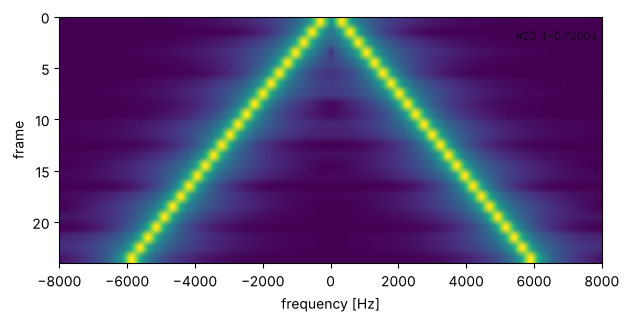

In [15]:
spec = plot.spectrum(title="chirp", ylim=(-80, 10))
fall = plot.waterfall(rows=32)
run(
    dsp.chirp(f0=200, f1=6000, rate=16_000, n=512, frames=24)
    >> dsp.window
    >> spec
    >> dsp.to_complex
    >> fall
)
fall.figure

In [16]:
spec.html(interval=80)  # JavaScript animation player

## 6b. `[]` selects ports, annotations and ancestors
Tuple outputs (fan-out, zip, multi-output blocks) expose ports; frames and provenance are indexable too.

130.0195290056301 | rate: 48000.0 | ancestors: ['[energy]', 'energy', 'sine'] | source seq: 2


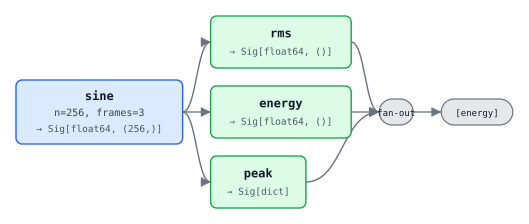

In [17]:
g = dsp.sine(n=256, frames=3) >> (dsp.rms | dsp.energy | dsp.peak)["energy"]
f = run(g)[-1]
print(
    f.data,
    "| rate:",
    f["rate"],
    "| ancestors:",
    [n.op for n in f.prov.chain()],
    "| source seq:",
    f.prov["sine"].seq,
)
g.draw()

In [18]:
@source
def spd() -> Sig[float, (3, 3)]:
    a = np.random.default_rng(0).normal(size=(3, 3))
    yield a @ a.T


eigh = block(
    np.linalg.eigh,
    inputs=Sig["T", ("N", "N")],
    outputs={"vals": Sig[float, "N"], "vecs": Sig["T", ("N", "N")]},
)
try:
    (
        spd() >> eigh["vals"] >> linalg.transpose
    )  # a vector is not a matrix: rejected at build time
except TypeMismatch as e:
    print("rejected:", e)
run(spd() >> eigh["vals"])[0]

rejected: [vals] -> transpose: rank 1 produced, rank 2 required (Sig[float64, (N,)] -> Sig[T, (M, N)])


data,"ndarray(3,) float64"
provenance,[vals]() #0 eigh(UPLO='L') #0 spd() #0


## 7. Linear algebra with explicit dimension contracts

In [19]:
@source
def snapshots(
    channels: int = 4, samples: int = 128, frames: int = 2
) -> Sig[complex, ("M", "N")]:
    rng = np.random.default_rng(0)
    steer = np.exp(1j * np.pi * np.arange(channels) * np.sin(np.deg2rad(20)))
    for _ in range(frames):
        s = np.exp(2j * np.pi * 0.05 * np.arange(samples))
        yield np.outer(s, steer) + 0.3 * (
            rng.normal(size=(samples, channels))
            + 1j * rng.normal(size=(samples, channels))
        )


cov = snapshots() >> linalg.covariance >> linalg.eigh
for fr in run(cov):
    print(np.round(fr.data[0], 2))
cov

[0.15 0.16 0.19 4.2 ]
[0.18 0.19 0.21 4.16]


node,in,out,kind
"snapshots(channels=4, samples=128, frames=2)",,"Sig[complex128, (M, N)]",source
covariance(),"Sig[T, (M, N)]","Sig[T, (N, N)]",map
eigh(),"Sig[T, (N, N)]","(Sig[float64, (N,)], Sig[T, (N, N)])",map
